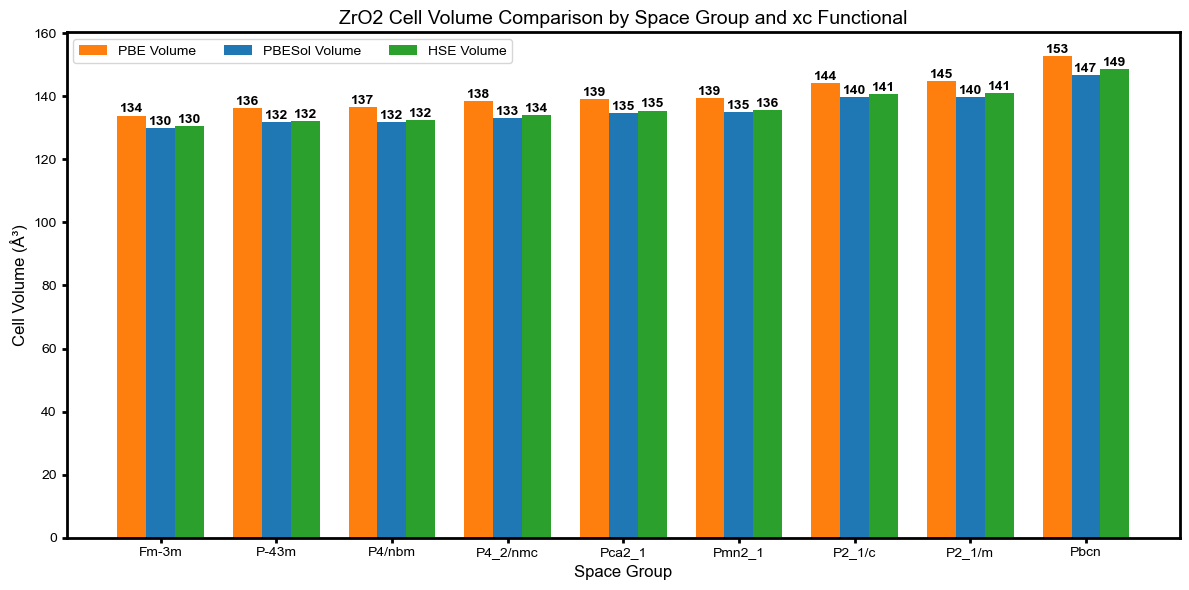

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

matplotlib.rcParams['font.family'] = 'Arial'

def calc_cell_volume(a, b, c, alpha, beta, gamma):
    # convert angles from degress to radians
    alpha_r, beta_r, gamma_r = np.radians([alpha, beta, gamma])

    # the formula of the cell volume
    volume = a * b * c * np.sqrt(
        1 - np.cos(alpha_r)**2 - np.cos(beta_r)**2 - np.cos(gamma_r)**2 + 
        2 * np.cos(alpha_r) * np.cos(beta_r) * np.cos(gamma_r)
    )
    return volume

file_path = 'structure_data_grouped_.csv'
df = pd.read_csv(file_path)

for method in ['PBE', 'PBESol', 'HSE']:
    df[f"{method} Volume"] = df.apply(lambda row: calc_cell_volume(
        row[f"{method} a"], row[f"{method} b"], row[f"{method} c"],
        row[f"{method} alpha"], row[f"{method} beta"], row[f"{method} gamma"]
    ), axis=1)

# sort the DataFrame by PBE Volume
df = df.sort_values(by="PBE Volume")


def add_value_labels(bars):
    """
    Function to add value labels on top of the bars in a bar chart.
    
    Parameters:
    bars (list): List of bar containers returned by the bar plot function.
    """
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.01,
            f"{round(height)}",  # Format the height to two decimal places
            ha='center', va='bottom', fontsize=10, color='black', rotation=0,
            # set bold
            fontweight='bold'
        )



# plt.style.use('seaborn-v0_8-whitegrid')

x_labels = df['Space Group']
x = np.arange(len(x_labels))  # the label locations

pbe_vol = df["PBE Volume"]
pbesol_vol = df["PBESol Volume"]
hse_vol = df["HSE Volume"]

width = 0.25  # the width of the bars
fig, ax = plt.subplots(figsize=(12, 6))

bars1 = ax.bar(x - width, pbe_vol, width=width, label='PBE Volume', color='tab:orange')
bars2 = ax.bar(x, pbesol_vol, width=width, label='PBESol Volume', color='tab:blue')
bars3 = ax.bar(x + width, hse_vol, width=width, label='HSE Volume', color='tab:green')

add_value_labels(bars1)
add_value_labels(bars2)
add_value_labels(bars3)

ax.set_xlabel('Space Group', fontsize=12)
ax.set_ylabel('Cell Volume (Å³)', fontsize=12)
ax.set_title('ZrO2 Cell Volume Comparison by Space Group and xc Functional', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(x_labels)
ax.tick_params(axis='both', width=2)

for spine in ax.spines.values():
    spine.set_linewidth(2)

ax.legend(ncols = 3)
ax.grid(False)
plt.tight_layout()
plt.savefig('cell_volume_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

df.to_csv('structure_data_with_volumes.csv', index=False, columns=["Space Group", "PBE Volume", "PBESol Volume", "HSE Volume"])